# HLLC Riemann solver

### Setup

In [1]:
import matplotlib.pyplot as pl
import numpy as np
import time

### HLLC

In [2]:
def hllc(lr,gamma=1.4,verbose=0,diag=None):
    qleft,qright=lr
    
    if gamma==1:
        g1=1.
    else:
        g1=1./(gamma-1.0)
    i,n=qleft.shape
    flux=np.zeros((4,n))
    
    if type(diag) is dict:
        diag['case']=[]
        diag['SSL']=[]
        diag['SSR']=[]
        diag['ro']=[]
        diag['uo']=[]
        diag['Po']=[]
        diag['so']=[]

    for i in range(n):
        # Left variables
        rl=qleft[0,i]
        Pl=qleft[1,i]
        ul=qleft[2,i]
        sl=qleft[3,i]
        tgl=qleft[4,i]
        el=qleft[5,i]

        # Right variables
        rr=qright[0,i]
        Pr=qright[1,i]
        ur=qright[2,i]
        sr=qright[3,i]
        tgr=qright[4,i]
        er=qright[5,i]

        # Find the largest eigenvalues in the normal direction to the interface
        cfastl = (gamma*Pl/rl)**0.5
        cfastr = (gamma*Pr/rr)**0.5

        # HLL wave speed
        SSL=min(ul,ur)-max(cfastl,cfastr)
        SSR=max(ul,ur)+max(cfastl,cfastr)

        # Sample the solution at x/t=0
        if SSL > 0.0:       # supersonic positive speed
            icase=1
            ro=rl
            uo=ul
            Po=Pl
            so=sl
            eo=el
            tgo=tgl
            scond = SSL*(np.log(Po)-np.log(ro)*gamma)
        elif SSR < 0.0:     # supersonic negative speed
            icase=4
            ro=rr
            uo=ur
            Po=Pr
            so=sr
            eo=er
            tgo=tgr
            scond = -0.5*uo*(np.log(Po/ro**gamma))
        else:
            # Lagrangian sound speed
            rcl=rl*(ul-SSL)
            rcr=rr*(SSR-ur)

            # Acoustic star state
            uo=(rcr*ur   +rcl*ul   +  (Pl-Pr))/(rcr+rcl)
            Po=(rcr*Pl+rcl*Pr+rcl*rcr*(ul-ur))/(rcr+rcl)

            # Left / right star region variables
            if uo > 0.0:        # positive momentum transport
                icase=2
                ro=rl*(SSL-ul)/(SSL-uo)
                eo=el*(SSL-ul)/(SSL-uo)
                tgo=tgl*(SSL-ul)/(SSL-uo)
                so=(SSL-ul)/(SSL-uo)*(sl+np.log(Pl/Po)-np.log(rl/ro)*gamma)
                scond=0
            else:               # negative momentum transport
                icase=3
                ro=rr*(SSR-ur)/(SSR-uo)
                eo=er*(SSR-ur)/(SSR-uo)
                tgo=tgr*(SSR-ur)/(SSR-uo)
                so=(SSR-ur)/(SSR-uo)*(sr-(np.log(Pr/Po)-np.log(rr/ro)*gamma))
                scond=0
        if verbose:
            pbzrint(('{:4d}{:3d}'+8*'{:8.3f}').format(i,icase,SL,SR,SAL,SAR,ro,uo,Po,eo))

        if type(diag) is dict:
            diag['case'].append(icase)
            diag['SSL'].append(SSL)
            diag['SSR'].append(SSR)
            diag['ro'].append(ro)
            diag['uo'].append(uo)
            diag['Po'].append(Po)
            diag['so'].append(so)

        flux[0,i] = ro*uo
        flux[1,i] = uo*(so)#+np.log(Po)-np.log(ro)*gamma)#+uo*scond
        flux[2,i] = ro*uo*uo+Po
        flux[3,i] = 0.5*ro*uo*uo**2

    return flux

n=1000
left=np.ones((6,n))
rght=np.ones((6,n))

start=time.time()
flux=hllc((left,rght))
print('{:.1f} microsec/cell'.format(1e6*(time.time()-start)/n))

20.8 microsec/cell


The entropy change $dS$ is given by
$$
TdS = dE + PdV
$$
as enthalpy is 
$$
H=E+PV,
$$
and 
$$dH = dE + PdV +VdP$$
hence
$$
TdS = dH - VdP = mc_pdT - \frac{mRT}{P}dP
$$
the entropy change per unit mass is
$$
\frac{dS}{m}=c_p\frac{dT}{T}-R\frac{dP}{P}
$$
integrating we have
$$
\frac{S_2-S_1}{m} = c_p\frac{dT}{T}-R\frac{dP}{P}
$$
by using $P=\rho RT$ we get
$$
\frac{S_2 - S_1}{mc_v} = c_pln\left(\frac{P_2}{P_1}\right)+c_pln\left(\frac{\rho_1}{\rho_2}) -Rln\left(\frac{P_2}{P_1})\\
\frac{S_2 - S_1}{mc_v} = c_vln\left(\frac{P_2}{P_1}+c_pln\left(\frac{\rho_1}{\rho_2}
$$
hence
$$
\frac{S_2 - S_1}{mc_v} = ln\left(\frac{P_2}{P_1}-\gamma ln\left(\frac{\rho_2}{\rho_1}
$$

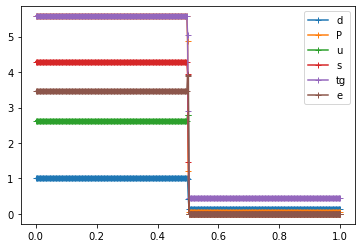

In [15]:
dtds=0.1
nstep=1
x,f=IC('shu_osher',n=400)
for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))

labels=['d','P','u','s','tg','e']
vv=ctoprim(f)
for i in range(0,vv.shape[0]):
    v = vv[i]
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

### Slope limiter (MonCen)

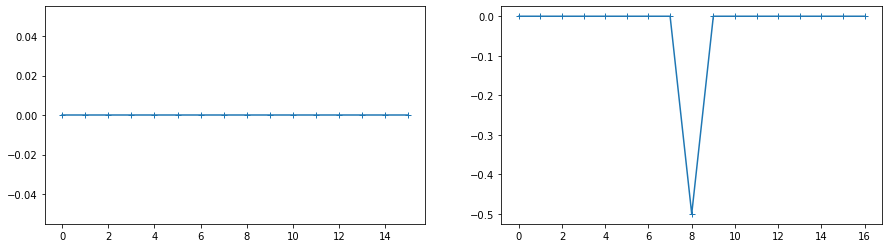

In [4]:
def moncen(q):
    n=len(q)
    df=np.zeros(n)

    for i in range(1,n-1):
        dl = q[i  ] - q[i-1]
        dr = q[i+1] - q[i  ]
        dc = 0.5*(dl+dr)
        sl = 2.*min(abs(dl),abs(dr)) if dl*dr > 0 else 0
        df[i] = np.sign(dc)*min(sl,abs(dc))

    df[0]=0.0
    df[-1]=0.0
    return df

def slope(q,method='moncen'):
    if method=='moncen':
        return moncen(q)

def slopes(f,method='moncen'):
    df=np.zeros(f.shape)
    for i,v in enumerate(f):
        df[i]=slope(v,method=method)
    return df

pl.figure(figsize=(15,4))
a=np.zeros(16); b=np.zeros(17)
for i in range(0,8):
    a[i]=1; b[i]=1
b[8]=0.5
#pl.subplot(1,2,1); n=16; pl.plot(slope(np.cos(np.linspace(0,2*np.pi,n+1))),'-+');
#pl.subplot(1,2,2); n=17; pl.plot(slope(np.cos(np.linspace(0,2*np.pi,n+1))),'-+');
pl.subplot(1,2,1); n=16; pl.plot(slope(a),'-+');
pl.subplot(1,2,2); n=17; pl.plot(slope(b),'-+');

### Shock initial conditions

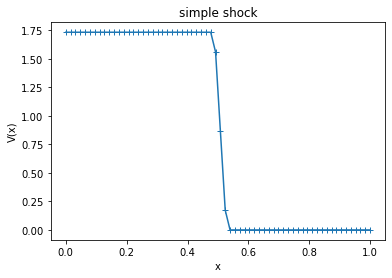

In [5]:
def simple_shock(n=64,pl=2,pr=1, rl=1.0, rr=1.0,gamma=1.4,m=None):
    x=np.linspace(0,1,n)
    if m is None:
        m=n//2
    f=np.zeros((3,n))
    f[0]=1.0
    f[2]=0.0
    f[1,0:m]=(np.log(pl)-np.log(rl)*gamma)  * rl / (gamma - 1.0)
    f[1,m:n]=(np.log(pr)-np.log(rr)*gamma)  * rr / (gamma - 1.0)
    f[1,m-1]=0.9*f[1,m-2]+0.1*f[1,m+2]
    f[1,m  ]=0.5*f[1,m-2]+0.5*f[1,m+2]
    f[1,m+1]=0.1*f[1,m-2]+0.9*f[1,m+2]
    return x,f

def sod(n=64,pl=1,pr=0.1,rl=1.0, rr=0.125,gamma=1.4,m=None):
    x=np.linspace(0,1,n)
    if m is None:
        m=n//2
    f=np.zeros((5,n))
    f[0,0:m]=1.0
    f[0,m:n]=0.125
    f[2]=0.0
    f[1,0:m]=(np.log(pl)-np.log(rl)*gamma)  * rl / (gamma - 1.0)
    f[1,m:n]=(np.log(pr)-np.log(rr)*gamma)  * rr / (gamma - 1.0)
    #f[1,m-1]=0.9*f[1,m-2]+0.1*f[1,m+2]
    #f[1,m  ]=0.5*f[1,m-2]+0.5*f[1,m+2]
    #f[1,m+1]=0.1*f[1,m-2]+0.9*f[1,m+2]
    return x,f

def shu_osher(n=64,pl=10.33333,pr=1.0,rl=3.857143, rr=1.0, ul=2.629369, ur=0.0, gamma=1.4,m=None):
    x=np.linspace(0,1,n)
    if m is None:
        m=n//2
    f=np.zeros((4,n))
    f[0,0:m]=1.0
    f[0,m:n]=0.125
    f[2,0:m]=ul
    f[2,m:n]=ur
    f[1,0:m]=(np.log(pl)-np.log(rl)*gamma)  * rl / (gamma - 1.0)
    f[1,m:n]=(np.log(pr)-np.log(rr)*gamma)  * rr / (gamma - 1.0)
    #f[1,m-1]=0.9*f[1,m-2]+0.1*f[1,m+2]
    #f[1,m  ]=0.5*f[1,m-2]+0.5*f[1,m+2]
    #f[1,m+1]=0.1*f[1,m-2]+0.9*f[1,m+2]
    return x,f

def IC(case='simple_shock',**kwarg):
    if case=='simple_shock':
        return simple_shock(**kwarg)
    if case=='SOD':
        return sod(**kwarg)
    if case=='shu_osher':
        return shu_osher(**kwarg)

x,f=IC()
pl.plot(x,f[1],'-+');
pl.xlabel('x'); pl.ylabel('V(x)'); pl.title('simple shock');

### Primitive variables

In [6]:
def ctoprim(f,gamma=1.4):
    m,n=f.shape
    d=f[0]
    s=f[1]
    p=f[2]
    u=p/d
    e=0.5*u*u
    p=d**gamma*np.exp(s/d*(gamma-1))
    tg=p/d
    return np.array((d,p,u,s,tg,e))

### Predictor

In [7]:
def predict(f):
    left=[]
    rght=[]
    for v in f:
        dv=slope(v)
        left.append(v+0.5*dv)
        rght.append(v-0.5*dv)
    left=np.roll(left,1,axis=1)
    left[:,0]=left[:,1]
    return np.array(left),np.array(rght)

Test

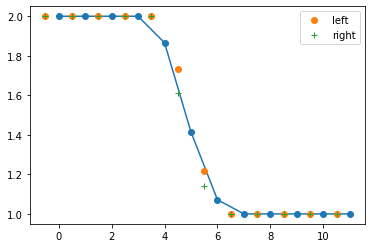

In [8]:
n=12
x,f=simple_shock(n=n,m=5)
x=np.arange(n)
p=ctoprim(f)
l,r=predict(p)
pl.plot(x,p[1],'-o')
pl.plot(x-0.5,l[1],'o',label='left')
pl.plot(x-0.5,r[1],'+',label='right')
pl.legend();

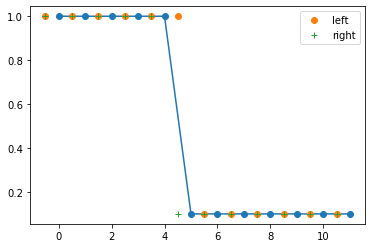

In [9]:
n=12
x,f=sod(n=n,m=5)
x=np.arange(n)
p=ctoprim(f)
l,r=predict(p)
pl.plot(x,p[1],'-o')
pl.plot(x-0.5,l[1],'o',label='left')
pl.plot(x-0.5,r[1],'+',label='right')
pl.legend();

### Flux

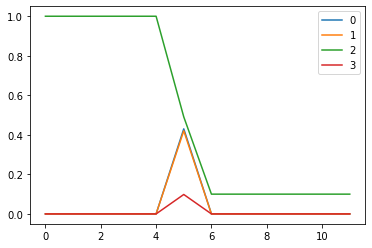

In [10]:
flux=hllc((l,r))
for i,v in enumerate(flux):
    pl.plot(v,label=i)
pl.legend();

### Boundary conditions

In [11]:
def BCs(df):
    df[:,0]=0.0
    df[:,-1]=0.0
    return df

### Flux divergence

In [12]:
def div(flux):
    df=np.roll(flux,-1,axis=1)-flux
    df[:,0]=0.0
    return df

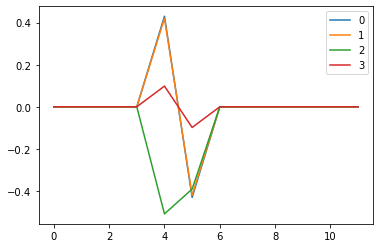

In [13]:
df=BCs(div(flux))
for i,v in enumerate(df):
    pl.plot(v,label=i)
pl.legend();

## Complete experiment

In [14]:
dtds=0.1
nstep=400
x,f=IC('SOD',n=200)
for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))

labels=['d','P','u','s','tg']
vv=ctoprim(f)
for i in range(0,vv.shape[0]-1):
    v = vv[i]
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

ValueError: operands could not be broadcast together with shapes (5,200) (4,200) (5,200) 

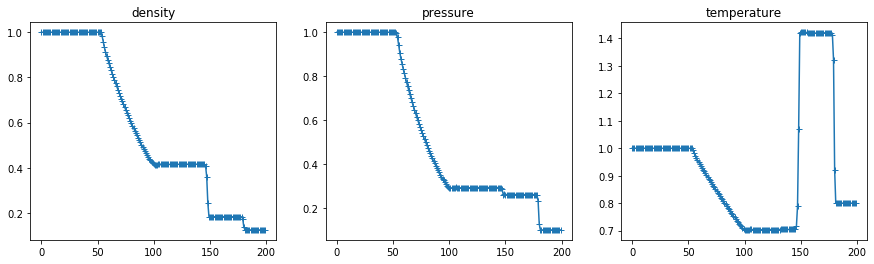

In [33]:
prim=ctoprim(f)
pl.figure(figsize=(15,4))
pl.subplot(1,3,1); pl.plot(prim[0],'-+'); pl.title('density')
pl.subplot(1,3,2); pl.plot(prim[1],'-+'); pl.title('pressure')
pl.subplot(1,3,3); pl.plot(prim[1]/prim[0],'-+'); pl.title('temperature');

### Local diagnostics

In [31]:
diag={}
pred=predict(ctoprim(f))
flux=hllc(pred,diag=diag)
diag.keys()

dict_keys(['case', 'SSL', 'SSR', 'ro', 'uo', 'Po', 'so'])

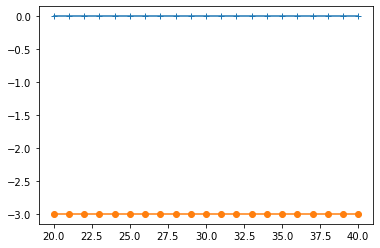

In [32]:
ii=20+np.arange(21)
pl.plot(ii,np.array(diag['uo'])[ii],'-+');
pl.plot(ii,flux[2,ii]-4,'-o');